# CNN for Colored Image Classification

### 1.Import Necessary Libraries

In [77]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

### 2.Import Dataset

In [78]:
TRAIN_DIR = r"C:\Users\kavin\Desktop\Datascience\Deep learning\13.Convolutional Neural Network\Image Classification\train_data"
VAL_DIR =  r"C:\Users\kavin\Desktop\Datascience\Deep learning\13.Convolutional Neural Network\Image Classification\val_data"
TEST_DIR = r"C:\Users\kavin\Desktop\Datascience\Deep learning\13.Convolutional Neural Network\Image Classification\test_data"

### 3.Image Normalization

In [79]:
# Image configuration
IMG_SIZE = (150, 150) # Resizes all images to 150x150 pixels
BATCH_SIZE = 16         # Low batch size because your dataset is very small
EPOCHS = 20            # Number of training loops
train_datagen = ImageDataGenerator(
                rescale= 1./255 ,
                rotation_range = 20,
                zoom_range = 0.2,
                shear_range = 0.2,
                horizontal_flip = True
)
val_test_datagen = ImageDataGenerator(rescale= 1./255)

In [80]:
train_data = train_datagen.flow_from_directory(TRAIN_DIR,
                                                target_size=IMG_SIZE,
                                                color_mode='rgb',
                                                class_mode='categorical',
                                                batch_size=BATCH_SIZE)

test_data = val_test_datagen.flow_from_directory(TEST_DIR,
                                                target_size=IMG_SIZE,
                                                color_mode='rgb',
                                                class_mode='categorical',
                                                batch_size=BATCH_SIZE)

val_data = val_test_datagen.flow_from_directory(VAL_DIR,
                                                target_size=IMG_SIZE,
                                                color_mode='rgb',
                                                class_mode='categorical',
                                                batch_size=BATCH_SIZE,
                                                shuffle=False)

Found 26 images belonging to 3 classes.
Found 9 images belonging to 3 classes.
Found 9 images belonging to 3 classes.


In [81]:
print("Class indices:", train_data.class_indices)
print("Classes:", list(train_data.class_indices.keys()))

NUM_CLASSES = train_data.num_classes

print("Number of classes:", NUM_CLASSES)

Class indices: {'ajith': 0, 'kamalahasan': 1, 'surya': 2}
Classes: ['ajith', 'kamalahasan', 'surya']
Number of classes: 3


### 4.Model building

In [82]:
model = models.Sequential([

    # Input image: 150 x 150 x 3
    layers.Input(shape=(150, 150, 3)),

    # First Convolution Block
    layers.Conv2D(filters=32,kernel_size=(3, 3),activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second Convolution Block
    layers.Conv2D(filters=64,  kernel_size=(3, 3), activation='relu' ),
    layers.MaxPooling2D(pool_size=(2, 2) ),

    # Third Convolution Block
    layers.Conv2D(filters=128,kernel_size=(3, 3), activation='relu' ),
    layers.MaxPooling2D( pool_size=(2, 2) ),

   # forth Convolution Block
    layers.Conv2D(filters=256,kernel_size=(3, 3), activation='relu' ),
    layers.MaxPooling2D( pool_size=(2, 2) ),
    
    
    # Convert feature maps into one-dimensional vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu' ),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(NUM_CLASSES, activation='softmax')
])

In [83]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [84]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)                   │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_15 (MaxPooling2D)      │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_16 (Conv2D)                   │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_16 (MaxPooling2D)      │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_17 (MaxPooling2D)      │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_18 (Conv2D)                   │ (None, 15, 15, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_18 (MaxPooling2D)      │ (None, 7, 7, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,994,563 (7.61 MB)

 Trainable params: 1,994,563 (7.61 MB)

 Non-trainable params: 0 (0.00 B)

In [85]:
# early_stopping = tf.keras.callbacks.EarlyStopping(
#     monitor='val_loss',
#     patience=5,
#     restore_best_weights=True
# )
# checkpoint = tf.keras.callbacks.ModelCheckpoint(
#     'best_cnn_model.keras',
#     monitor='val_accuracy',
#     save_best_only=True,
#     mode='max'
# )


In [86]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    # callbacks=[
    #     early_stopping,
    #     checkpoint
    # ]
)

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 475ms/step - accuracy: 0.3462 - loss: 1.1341 - val_accuracy: 0.3333 - val_loss: 1.1435
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.3846 - loss: 1.2861 - val_accuracy: 0.3333 - val_loss: 1.0966
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 446ms/step - accuracy: 0.3077 - loss: 1.1480 - val_accuracy: 0.3333 - val_loss: 1.1030
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 299ms/step - accuracy: 0.3846 - loss: 1.1279 - val_accuracy: 0.3333 - val_loss: 1.0970
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 292ms/step - accuracy: 0.2692 - loss: 1.1059 - val_accuracy: 0.3333 - val_loss: 1.0971
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 450ms/step - accuracy: 0.4231 - loss: 1.0907 - val_accuracy: 0.3333 - val_loss: 1.0966
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 294ms/step - accuracy: 0.3846 - loss: 1.0939 - val_accuracy: 0.3333 - val_loss: 1.0973
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 299ms/step - accuracy: 0.4615 - loss: 1.0790 - val_accuracy: 0.3333 - val_loss:

In [87]:
val_data = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
   
)

Found 9 images belonging to 3 classes.


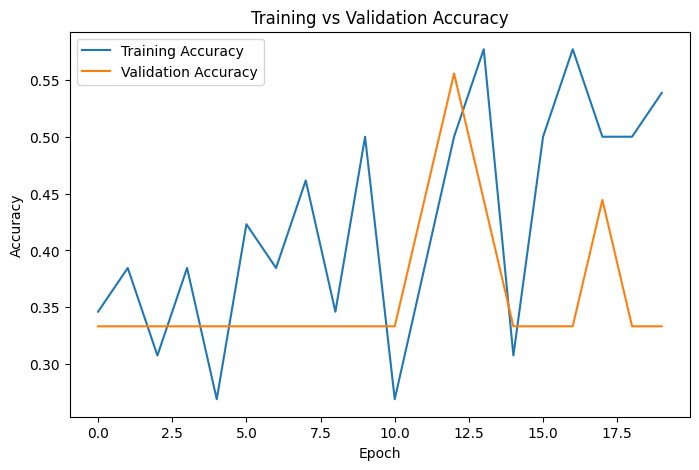

In [88]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Training vs Validation Accuracy')

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()

plt.show()

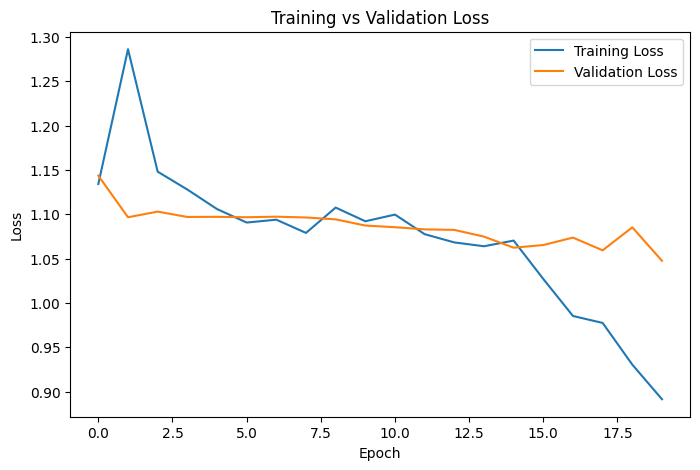

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training vs Validation Loss')

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.show()

In [90]:
val_loss, val_accuracy = model.evaluate(val_data)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.3333 - loss: 1.0475
Validation Loss: 1.0475438833236694
Validation Accuracy: 0.3333333432674408


In [91]:
predictions = model.predict(test_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step


In [92]:
predicted_classes = np.argmax(
    predictions,
    axis=1
)
predicted_classes
true_classes = test_data.classes

In [93]:
print("Actual:", true_classes)
print("Predicted:", predicted_classes)


Actual: [0 0 0 1 1 1 2 2 2]
Predicted: [0 0 2 0 2 2 2 0 0]


In [94]:
class_names = list(train_data.class_indices.keys())

print(class_names)
for actual, predicted in zip(
    true_classes,
    predicted_classes
):

    print(
        f"Actual: {class_names[actual]} "
        f"| Predicted: {class_names[predicted]}"
    )

['ajith', 'kamalahasan', 'surya']
Actual: ajith | Predicted: ajith
Actual: ajith | Predicted: ajith
Actual: ajith | Predicted: surya
Actual: kamalahasan | Predicted: ajith
Actual: kamalahasan | Predicted: surya
Actual: kamalahasan | Predicted: surya
Actual: surya | Predicted: surya
Actual: surya | Predicted: ajith
Actual: surya | Predicted: ajith


In [95]:
from sklearn.metrics import confusion_matrix

In [96]:
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

print(cm)

[[2 0 1]
 [1 0 2]
 [2 0 1]]


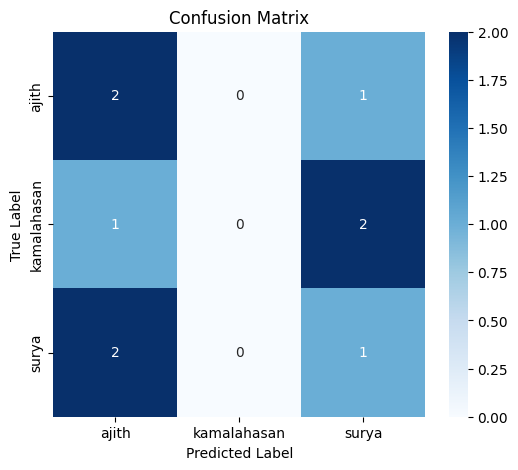

In [97]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')

plt.ylabel('True Label')

plt.title('Confusion Matrix')

plt.show()

In [98]:
from sklearn.metrics import classification_report

In [99]:
report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

       ajith       0.40      0.67      0.50         3
 kamalahasan       0.00      0.00      0.00         3
       surya       0.25      0.33      0.29         3

    accuracy                           0.33         9
   macro avg       0.22      0.33      0.26         9
weighted avg       0.22      0.33      0.26         9



C:\Users\kavin\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\kavin\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\kavin\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [100]:
# model.save("person_cnn_model.keras")